# Selective prediction with probly

## API Overview

#### Selector

```python
selector(threshold=... | coverage=... | risk=..., delta=...)
```
builds the rule that decides accept or abstain per instance.

- ``threshold`` builds ``ThresholdSelector``,
- ``coverage`` builds ``CoverageSelector``,
- ``risk`` with ``delta`` builds ``SGRSelector``.

The Selector subclasses are internal and not exported.

All three accept an instance if its criterion is at most the threshold. While we directly set a threshold for the ``ThresholdSelector``, ``CoverageSelector`` and ``SGRSelector`` fit their thresholds with ``.calibrate()``.

| Rule  | Guarantee | Labels | Loss |
|-------|-----------|--------|------|
| threshold | none (Chow's rule on the default criterion) | no | any |
| coverage | $P(\text{accepted}) \ge c$, marginal | no | any |
| risk | selective risk $\le r$ with probability $\ge 1 - \delta$ | yes | zero-one only |

Under the default zero-one loss, the criterion is the model's own probability that its prediction is wrong. A fixed threshold $t$ on it is Chow's rule: if an error costs 1 and abstaining costs $t$, abstain whenever the expected cost of predicting exceeds $t$. ``threshold=0.2`` abstains when the model puts more than 20% probability on being wrong.

#### Wrapper

```python
selective_predictor(model, selector=..., notion=..., loss=..., decider=..., representer_kwargs=...)
```

wraps a model. 
- ``notion`` defaults to "total" uncertainty, but also accepts a function mapping the representation to the criterion per instance.
- ``loss`` defaults to ``ZeroOneLoss``. It picks the decomposition that a named ``notion`` comes from and it gives the per-instance losses of the decisions for SGR calibration and ``evaluate``. A function ``loss(decision, y)`` works too. With ``loss=None`` the criterion comes from ``quantify`` and evaluate and the risk selector raise.
- ``decider`` maps the representation to the decision, defaults to ``categorical_from_mean``.
- ``representer_kwargs`` are passed to the representer.

#### Calibrate

```python
sp.calibrate(y_cal, X_cal)
```

fits the threshold for coverage and risk selectors. Raises on ``ThresholdSelector``.

``CoverageSelector`` uses split conformal prediction and needs no labels. With $n$ calibration instances, $\tau$ is the $\lceil (n+1)\cdot c\rceil$-th smallest calibration score. If calibration and test instances are exchangeable, a new instance is accepted with probability at least $c$, and at most about $c + 1/(n+1)$ if there are no ties. With many tied scores, e.g. the zero-one epistemic part, the coverage can be well above $c$. Calibration needs at least $c/(1-c)$ instances and raises otherwise. The risk is not controlled.

``SGRSelector`` uses SGR (Geifman & El-Yaniv) and needs labels. The goal is a selective risk of at most $r$ with probability at least $1 - \delta$ over the draw of the calibration set. A binary search over the sorted calibration criteria tests $\lceil \log_2 n \rceil$ thresholds, each with a one-sided Clopper-Pearson upper bound on the selective error at level $\delta / \lceil \log_2 n \rceil$ (union bound). It returns the last certified threshold, unlike the paper, which returns the last tested one. Calibration raises, when no threshold can be certified. The coverage is not controlled.

#### Predict

```python
sp.predict(x)
```
returns a ``SelectivePrediction`` with ``decision``, ``uncertainty``, ``accepted`` and ``coverage``.

#### Evaluate

```python
sp.evaluate(y, x, metrics=...)
```
does one forward pass over labeled data and returns a dict of floats: ``aurc``, ``augrc`` and ``risk@1``,  
plus ``selected:coverage`` and ``selected:risk``, when there is a selector.  
 ``metrics=...`` replaces the defaults, e.g. ``["aurc", "risk@0.8", "coverage@0.05"]``.

## Workflow example

Transforming, training, wrapping a model in ``selective_predictor`` and then calling it.

In [ ]:
import torch
from torch import nn
from sklearn.datasets import make_moons

from probly.selective_prediction import selective_predictor, selector
from probly.transformation import dropout

X_train, y_train = make_moons(n_samples=500, noise=0.35, random_state=0)
X_train, y_train = torch.from_numpy(X_train).float(), torch.from_numpy(y_train).long()

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
model = dropout(net, p=0.2, predictor_type="logit_classifier")

opt = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for _ in range(300):
    opt.zero_grad()
    nn.functional.cross_entropy(model(X_train), y_train).backward()
    opt.step()
model.eval()

sp = selective_predictor(model, selector=selector(threshold=0.2), representer_kwargs={"num_samples": 50})

x = torch.tensor([[0.0, 1.0], [0.5, 0.25], [3.0, 2.5]])  # inside a moon, between the moons, far away
with torch.no_grad():
    result = sp.predict(x)

print("decision   ", result.decision.probabilities.argmax(dim=-1).tolist())
print("uncertainty", [round(u, 3) for u in result.uncertainty.tolist()])
print("accepted   ", result.accepted.tolist())
print("coverage   ", result.coverage)

prediction  [0, 1, 0]
uncertainty [0.005, 0.417, 0.233]
accepted    [True, False, False]
coverage    0.3333333333333333


Evaluate the ``selective_predictor``.

In [14]:
X_test, y_test = make_moons(n_samples=500, noise=0.35, random_state=1)
X_test, y_test = torch.from_numpy(X_test).float(), torch.from_numpy(y_test).long()

torch.manual_seed(0)
with torch.no_grad():
    scores = sp.evaluate(y_test, X_test)
print({name: round(value, 3) for name, value in scores.items()})

{'aurc': 0.038, 'augrc': 0.026, 'risk@1': 0.116, 'selected:coverage': 0.772, 'selected:risk': 0.06}


- ``aurc`` is the area under the risk-coverage curve, i.e. the selective risk averaged over all coverages.
- ``augrc`` is the area under the generalized risk-coverage curve. The generalized risk is the selective risk times the coverage, that is, the loss of the accepted instances averaged over all instances ("risk of a silent failure"). Better suited for comparing criteria than ``aurc`` (Traub et al. 2024).

Both areas are threshold-free and lower is better.

- ``risk@1`` is the error rate without abstention. It is reported next to the areas, which alone cannot tell a better classifier from a better ranking of its errors.
- ``selected:coverage`` and ``selected:risk`` are the fraction accepted at the chosen threshold, and the error rate on those points. The gap to ``risk@1`` is what the selector gains.

Risk-coverage curve.

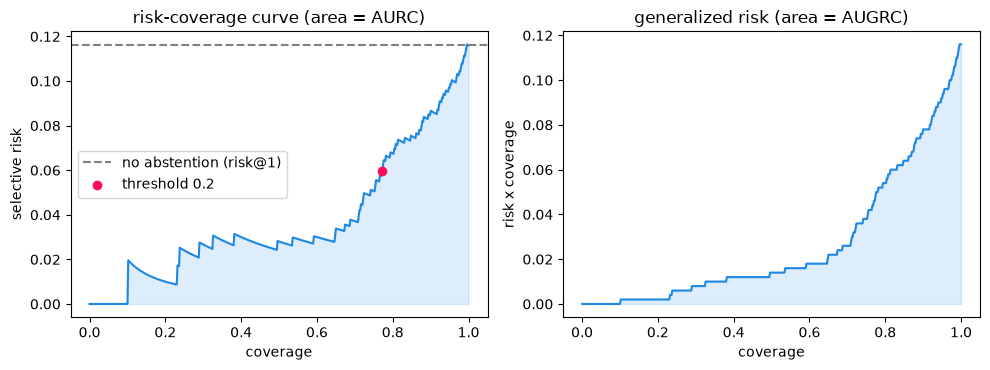

AUGRC from the curve: 0.026 evaluate: 0.026


In [15]:
import matplotlib.pyplot as plt
import numpy as np

from probly.metrics.selective_prediction import risk_coverage_curve

torch.manual_seed(0)  # same MC samples as the evaluate call above
with torch.no_grad():
    test = sp.predict(X_test)
errors = (test.decision.probabilities.argmax(dim=-1) != y_test).float()  # zero-one loss per instance
coverage, risk, _ = risk_coverage_curve(test.uncertainty, errors)
coverage, risk = coverage.numpy(), risk.numpy()

BLUE, RED = "#1e88e5", "#ff0d57"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, curve, title in [
    (axes[0], risk, "risk-coverage curve (area = AURC)"),
    (axes[1], risk * coverage, "generalized risk (area = AUGRC)"),
]:
    ax.plot(coverage, curve, color=BLUE)
    ax.fill_between(coverage, curve, alpha=0.15, color=BLUE)
    ax.set_title(title)
    ax.set_xlabel("coverage")
axes[0].axhline(scores["risk@1"], color="gray", linestyle="--", label="no abstention (risk@1)")
axes[0].scatter(scores["selected:coverage"], scores["selected:risk"], color=RED, zorder=3, label="threshold 0.2")
axes[0].set_ylabel("selective risk")
axes[1].set_ylabel("risk x coverage")
axes[0].legend()
plt.tight_layout()
plt.show()

area = float(np.trapezoid(risk * coverage, coverage))
print("AUGRC from the curve:", round(area, 3), "evaluate:", round(scores["augrc"], 3))

The most uncertain instances are rejected first. The x-axis is the fraction still accepted, the y-axis the error rate among them (left) or their errors counted over all instances (right). 

## Regression example

The default ``notion``, ``decider`` and ``loss`` assume a categorical representation. Regression needs a function for each.

In [16]:
from probly.transformation import ensemble

rng = np.random.default_rng(0)

# 1D data with a gap in the middle, so the model never sees x near 0
X = np.concatenate([rng.uniform(-4.5, -1, 40), rng.uniform(1, 4.5, 40)])
X = torch.from_numpy(X).float().reshape(-1, 1)
y = torch.sin(1.5 * X) + 0.12 * torch.from_numpy(rng.standard_normal(X.shape)).float()

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))
ens = ensemble(net, num_members=10, reset_params=True)

for member in ens:
    opt = torch.optim.Adam(member.parameters(), lr=0.01)
    for _ in range(400):
        opt.zero_grad()
        loss = nn.functional.mse_loss(member(X), y)
        loss.backward()
        opt.step()

In [17]:
def sine_data(n, seed):
    X = torch.linspace(-4.5, 4.5, n).reshape(-1, 1)
    noise = torch.randn(X.shape, generator=torch.Generator().manual_seed(seed))
    return X, (torch.sin(1.5 * X) + 0.12 * noise).squeeze(-1)

# Calibration and test inputs are two uniform grids over the same interval.
# The guarantee itself is for exchangeable draws.
X_cal, _ = sine_data(300, seed=1)
X_te, y_te = sine_data(400, seed=2)

In [18]:
sp = selective_predictor(
    ens,
    selector=selector(coverage=0.7),
    notion=lambda s: s.sample_var().squeeze(-1),    # criterion, variance across members
    decider=lambda s: s.sample_mean().squeeze(-1),  # decision, ensemble mean
    loss=lambda d, y: (d - y) ** 2,                 # squared error per instance
)

with torch.no_grad():
    sp.calibrate(None, X_cal)
    scores = sp.evaluate(y_te, X_te)
    test = sp.predict(X_te)
print({name: round(value, 3) for name, value in scores.items()})

{'aurc': 0.018, 'augrc': 0.009, 'risk@1': 0.025, 'selected:coverage': 0.705, 'selected:risk': 0.016}


``selected:coverage`` 0.705 is close to the 0.7 target. The selective MSE drops from 0.025 (``risk@1``) to 0.016.

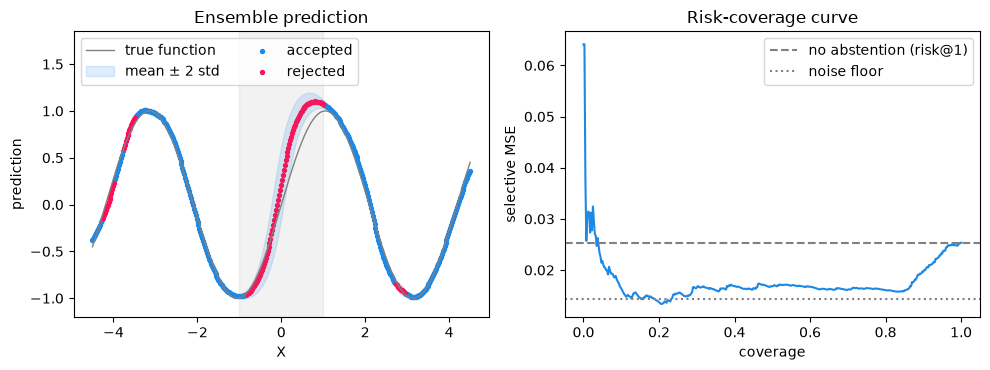

In [19]:
Xs = X_te.squeeze(-1).numpy()
mean = test.decision.numpy()
std = test.uncertainty.sqrt().numpy()  # the criterion, as a standard deviation
accepted = test.accepted.numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

ax = axes[0]
ax.plot(Xs, np.sin(1.5 * Xs), color="gray", lw=1, label="true function")
ax.fill_between(Xs, mean - 2 * std, mean + 2 * std, color=BLUE, alpha=0.15, label=r"mean $\pm$ 2 std")
ax.scatter(Xs[accepted], mean[accepted], s=8, color=BLUE, label="accepted")
ax.scatter(Xs[~accepted], mean[~accepted], s=8, color=RED, label="rejected")
ax.axvspan(-1, 1, color="gray", alpha=0.1)  # the gap without training data
ax.set(xlabel="X", ylabel="prediction", title="Ensemble prediction", ylim=(-1.2, 1.85))
ax.legend(loc="upper left", ncol=2)

ax = axes[1]
errors = (test.decision - y_te) ** 2  # same loss as above
coverage, risk, _ = risk_coverage_curve(test.uncertainty, errors)
ax.plot(coverage.numpy(), risk.numpy(), color=BLUE)
ax.axhline(scores["risk@1"], color="gray", linestyle="--", label="no abstention (risk@1)")
ax.axhline(0.12**2, color="gray", linestyle=":", label="noise floor")  # variance of the label noise
ax.set(xlabel="coverage", ylabel="selective MSE", title="Risk-coverage curve")
ax.legend()
plt.tight_layout()
plt.show()

The model saw no training data in the grey gap(-1, 1). The members disagree there, so most of the gap is among 30% most uncertain instances and is rejected. 

# Selective prediction on CIFAR-10

In [20]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.insert(0, "src")  # the experiment package, without installing it
from src.sgr_experiment.data import load_cifar10, normalize
from src.sgr_experiment.loaders import load_base
from src.sgr_experiment.utils import EXPERIMENT_DIR, run_dir

DATA_DIR, RUNS_DIR = EXPERIMENT_DIR / "data", EXPERIMENT_DIR / "runs"

In [21]:
# Helpers for showing data and results; the demos below only call them.
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CURVE = [f"risk@{c}" for c in np.round(np.arange(0.05, 1.01, 0.05), 2)]  # metrics that trace the risk-coverage curve
TABLE = (1, 0.9, 0.8, 0.7, 0.6, 0.5)  # coverages printed in the table


def show_evaluation(result: dict[str, float], title: str) -> None:
    """Print and plot a result of ``SelectivePredictor.evaluate``, whatever metrics were asked for.

    The panels are the classic plots of the metrics: the risk-coverage curve (AURC, with the ``coverage@r`` points as
    dots and the selector as a star) and the generalized risk curve (AUGRC).
    A ``risk@1`` carries no ``:coverage`` companion, its coverage is the target 1 itself.
    """
    risk_at = {float(k[5:]): (result.get(f"{k}:coverage", float(k[5:])), v) for k, v in result.items() if k.startswith("risk@") and ":" not in k}
    coverage_at = {k[9:]: (v, result[f"{k}:risk"]) for k, v in result.items() if k.startswith("coverage@") and ":" not in k}
    print("  ".join(f"{k} {result[k]:.4f}" for k in ("aurc", "augrc") if k in result))
    print("risk at coverage  " + "  ".join(f"{c:4.0%}: {risk_at[c][1]:.3f}" for c in TABLE if c in risk_at))
    print("coverage at risk  " + "  ".join(f"{float(r):4.0%}: {cov:.2f}" for r, (cov, _) in coverage_at.items()))
    if "selected:coverage" in result:
        print(f"selector          coverage {result['selected:coverage']:.2f}, risk {result['selected:risk']:.3f}")

    coverage, risk = np.array(sorted(risk_at.values())).T
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(coverage, risk, ".-")
    axes[0].fill_between(coverage, risk, alpha=0.2)
    for r, (cov, rk) in coverage_at.items():
        axes[0].plot(cov, rk, "o", color="tab:orange")  # NaN, so not drawn, if no coverage meets the risk
        axes[0].annotate(f"coverage@{float(r):.0%}", (cov, rk), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=8)
    if "selected:coverage" in result:
        axes[0].plot(result["selected:coverage"], result["selected:risk"], "*", color="tab:green", ms=14, label="selector")
        axes[0].legend(loc="upper left", fontsize=8)
    axes[1].plot(coverage, coverage * risk, ".-", color="tab:purple")
    axes[1].fill_between(coverage, coverage * risk, color="tab:purple", alpha=0.2)
    axes[0].set(ylabel="selective risk", title=f"AURC {result.get('aurc', np.nan):.4f}")
    axes[1].set(ylabel="generalized risk (coverage x risk)", title=f"AUGRC {result.get('augrc', np.nan):.4f}")
    for ax in axes:
        ax.set(xlim=(0, 1.02), ylim=(0, None), xlabel="coverage")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def show_images(x_u8: torch.Tensor, y: torch.Tensor, title: str) -> None:
    """Plot the first 16 uint8 images with their labels."""
    fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
    for ax, image, label in zip(axes.flat, x_u8, y):
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(CLASSES[int(label)], fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def show_selective(x_u8: torch.Tensor, y: torch.Tensor, predictions, title: str) -> None:
    """Plot images sorted by uncertainty, framed green if the model answers and red if it abstains.

    A wrong prediction is titled in red with its true class.
    """
    probabilities = predictions.decision.probabilities.cpu()
    decision = probabilities.argmax(dim=-1).numpy()
    uncertainty = torch.as_tensor(predictions.uncertainty).cpu().numpy()
    accepted = torch.as_tensor(predictions.accepted).cpu().numpy()
    wrong = decision != np.asarray(y)

    fig, axes = plt.subplots(len(y) // 8, 8, figsize=(12, 2.1 * (len(y) // 8)))
    for ax, i in zip(axes.flat, np.argsort(uncertainty, kind="stable")):
        ax.imshow(x_u8[i].permute(1, 2, 0).numpy())
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set(color="tab:green" if accepted[i] else "tab:red", linewidth=4)
        label = f"{CLASSES[decision[i]]} ({probabilities[i].max():.0%})" + (f", is {CLASSES[int(y[i])]}" if wrong[i] else "")
        ax.set_title(f"{label}\nunc {uncertainty[i]:.2f}", fontsize=7.5, color="tab:red" if wrong[i] else "black")
    fig.suptitle(f"{title}\naccepted {accepted.sum()} of {len(y)}, wrong among accepted {wrong[accepted].sum()}, "
                 f"wrong among abstained {wrong[~accepted].sum()}", fontsize=10)
    fig.tight_layout()
    plt.show()


def plot_series(series: np.ndarray, kinds: np.ndarray, predictions=None, quantiles=None, title: str = "") -> None:
    """Plot the first series of every kind; with ``predictions`` also its forecast and 10-90% band.

    An accepted forecast is green, an abstained one red.
    """
    past, future = np.arange(-2 * HORIZON, 0), np.arange(HORIZON)
    fig, axes = plt.subplots(len(KINDS), 1, figsize=(10, 2.6 * len(KINDS)), sharex=True)
    for ax, k in zip(axes, range(len(KINDS))):
        i = np.flatnonzero(kinds == k)[0]
        ax.plot(past, series[i, CONTEXT + past], lw=1, label="context")
        ax.plot(future, series[i, CONTEXT:], lw=1, label="true future")
        ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
        ax.set_title(f"new series {i}, {KINDS[k]}", fontsize=10)
        if predictions is not None:
            accepted = bool(predictions.accepted[i])
            color = "tab:green" if accepted else "tab:red"
            band = np.asarray(quantiles)[i]
            ax.fill_between(future, band[:, 1], band[:, 9], color=color, alpha=0.2, lw=0, label="10-90% band")
            ax.plot(future, predictions.decision[i], color=color, lw=1.5, label="forecast")
            ax.set_title(f"new series {i}, {KINDS[k]}: {'accepted' if accepted else 'abstained'}, "
                         f"mean band {predictions.uncertainty[i]:.2f}", fontsize=10, color=color)
    axes[0].legend(loc="upper left", fontsize=8, ncol=4)
    axes[-1].set_xlabel("steps from the forecast start")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


## CIFAR-10

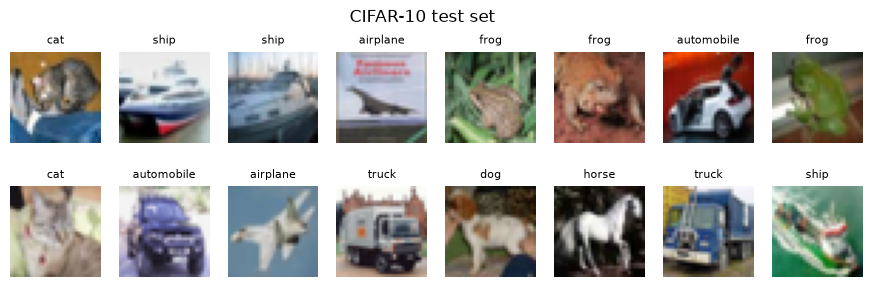

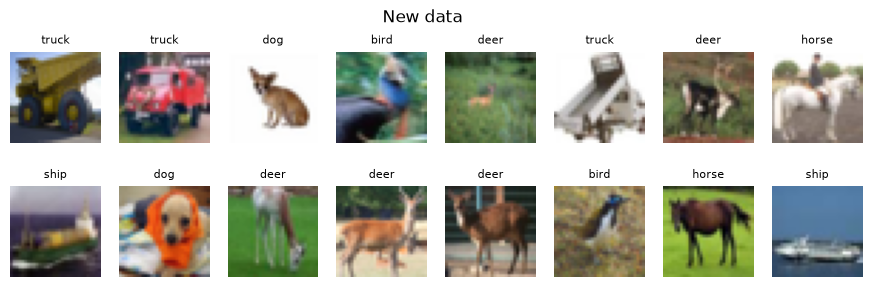

In [22]:
x_test_u8, y_test = load_cifar10(DATA_DIR, train=False)
x_test = normalize(x_test_u8)

# Half of the test set calibrates the selector, the rest evaluates it, and the last 24 images are new data.
perm = np.random.default_rng(0).permutation(len(y_test))
sel_idx, eval_idx, new_idx = perm[:5000], perm[5000:-24], perm[-24:]
x_sel, y_sel = x_test[sel_idx], y_test[sel_idx]
x_eval, y_eval = x_test[eval_idx], y_test[eval_idx]
x_new, y_new, x_new_u8 = x_test[new_idx], y_test[new_idx], x_test_u8[new_idx]

show_images(x_test_u8, y_test, "CIFAR-10 test set")
show_images(x_new_u8, y_new, "New data")

## Trained ensemble

The same predictor as `ensemble(model, ...)` in the demo, but with the five trained seeds (`runs/seed0` to
`runs/seed4`) as members instead of re-initialized copies.

In [23]:
from probly.method import ensemble

trained_ensemble = ensemble(
    load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16"), num_members=5, predictor_type="logit_classifier"
)
for seed, member in enumerate(trained_ensemble):
    member.load_state_dict(load_base(run_dir(RUNS_DIR, seed=seed) / "base.pt", arch="vgg16").state_dict())
    member.eval()

## Demo

aurc 0.0056  augrc 0.0041
risk at coverage  100%: 0.050   90%: 0.015   80%: 0.005   70%: 0.002   60%: 0.001   50%: 0.000
coverage at risk    1%: 0.86    3%: 0.96
selector          coverage 0.81, risk 0.005


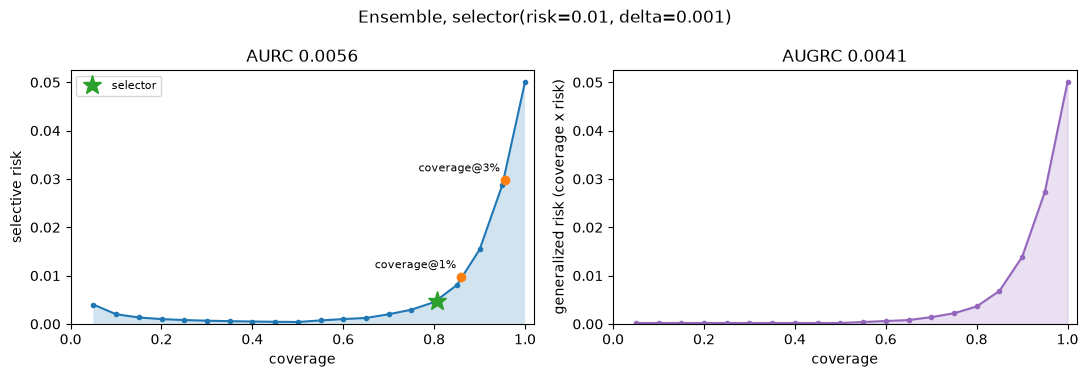

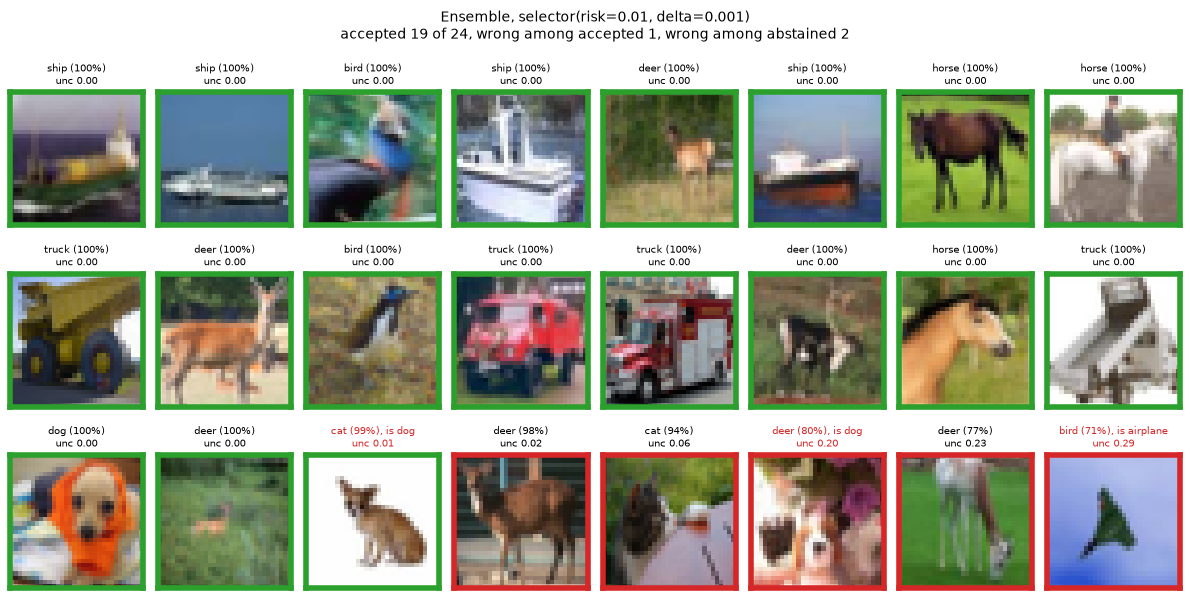

In [24]:
from probly.method import ensemble
from probly.selective_prediction import selector, selective_predictor

model = load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16")

# Make the model uncertainty-aware; the trained ensemble then replaces the untrained one.
ensemble_model = ensemble(model, num_members=5, reset_params=True, predictor_type="logit_classifier")
ensemble_model = trained_ensemble

# Accept as many images as possible with at most 1% errors among them.
selective_model = selective_predictor(ensemble_model, selector=selector(risk=0.01, delta=0.001))

with torch.no_grad():
    selective_model.calibrate(y_sel, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Ensemble, {selective_model.selector}")
show_selective(x_new_u8, y_new, predictions, title=f"Ensemble, {selective_model.selector}")

aurc 0.0093  augrc 0.0070
risk at coverage  100%: 0.064   90%: 0.025   80%: 0.012   70%: 0.005   60%: 0.004   50%: 0.004
coverage at risk    1%: 0.78    3%: 0.92
selector          coverage 0.80, risk 0.012


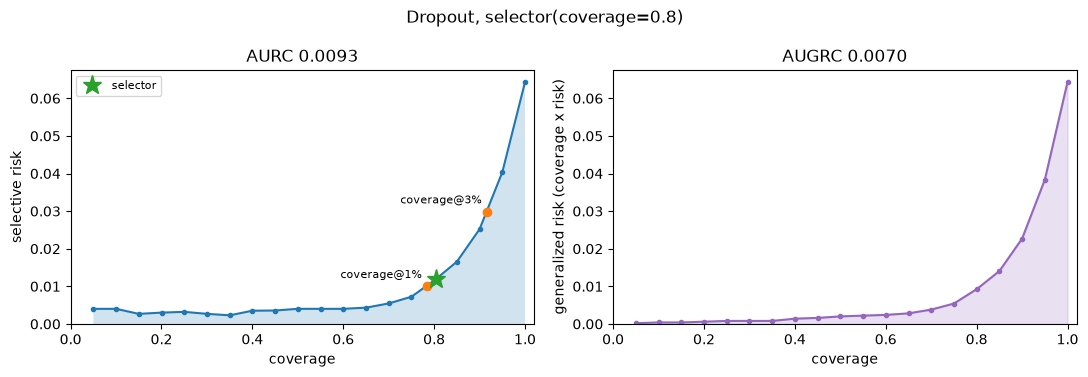

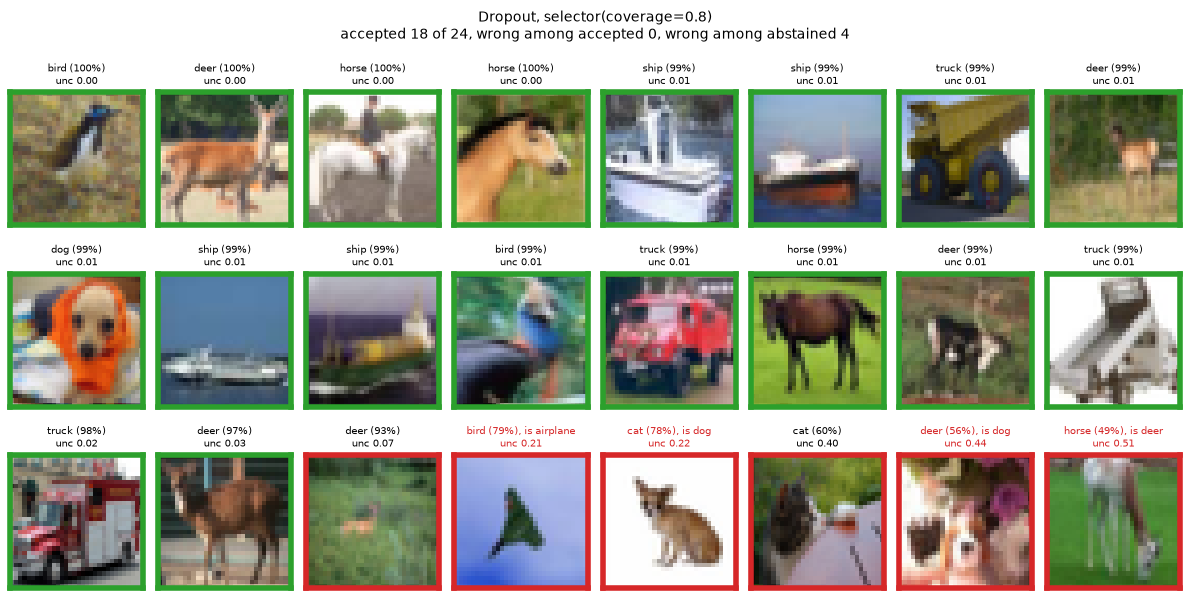

In [25]:
from probly.method import dropout

dropout_model = dropout(model, p=0.5, predictor_type="logit_classifier")

# Accept the 80% most certain images.
selective_model = selective_predictor(
    dropout_model, selector=selector(coverage=0.8), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    selective_model.calibrate(None, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}")
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")

aurc 0.0083  augrc 0.0068
risk at coverage  100%: 0.067   90%: 0.024   80%: 0.010   70%: 0.005   60%: 0.004   50%: 0.003
coverage at risk    1%: 0.80    3%: 0.92
selector          coverage 0.98, risk 0.054


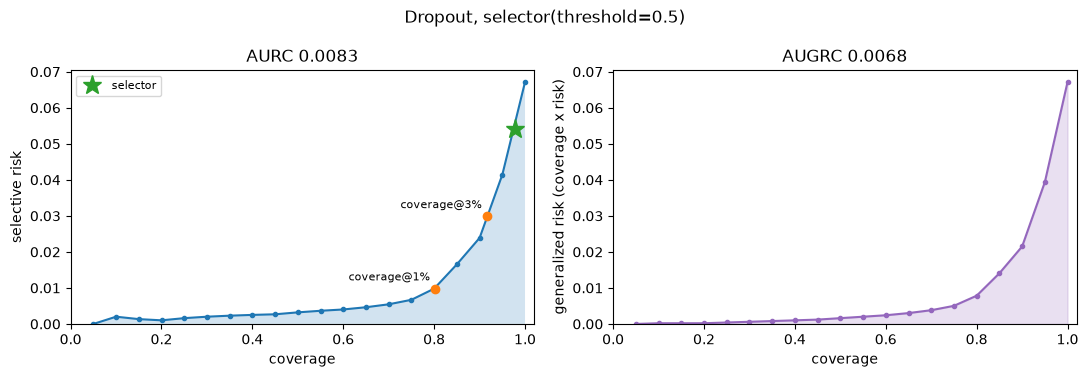

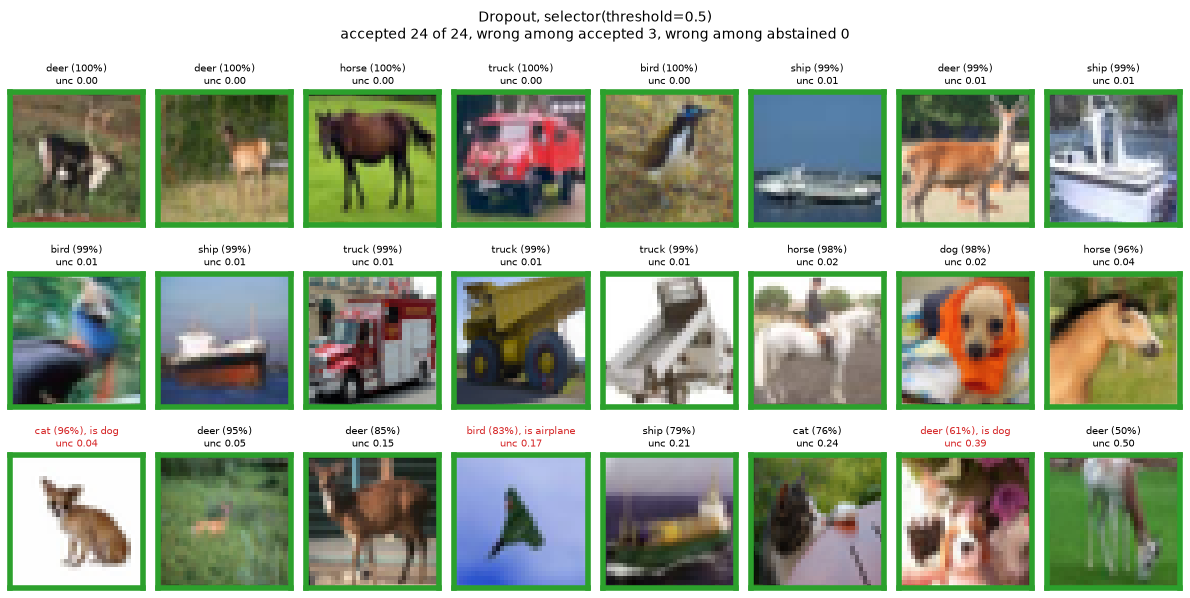

In [26]:
# Accept every image with an uncertainty below 0.5; a fixed threshold needs no calibration.
selective_model = selective_predictor(
    dropout_model, selector=selector(threshold=0.5), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}")
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")

## Expert Section

### Data

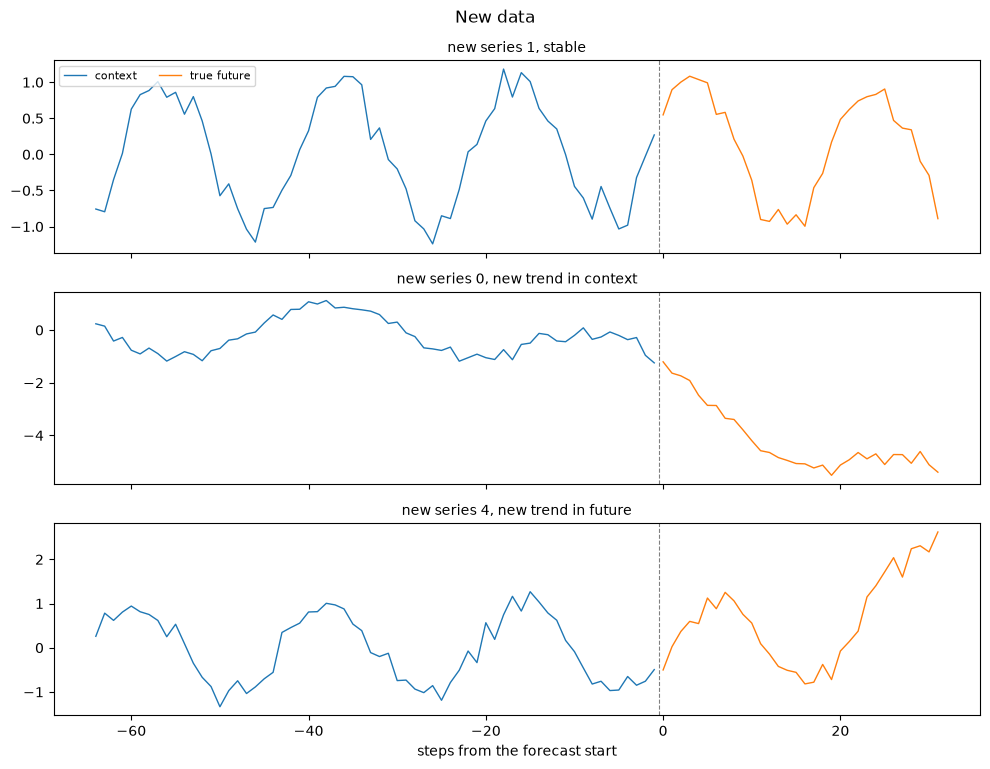

In [27]:
# Seasonal series of three kinds: most keep their pattern, some start a new trend shortly before the forecast
# (which the model has hardly seen in that series), and some start it only inside the forecast horizon.
CONTEXT, HORIZON = 256, 32  # steps observed, steps forecast
KINDS = ("stable", "new trend in context", "new trend in future")


def make_series(n: int, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    """``n`` series ``(n, CONTEXT + HORIZON)`` and their kind ``(n,)``."""
    t = np.arange(CONTEXT + HORIZON)
    period, phase = rng.integers(16, 40, size=(n, 1)), rng.uniform(0, 2 * np.pi, size=(n, 1))
    series = np.sin(2 * np.pi * t / period + phase) + 0.15 * rng.standard_normal((n, len(t)))
    kind = rng.choice(len(KINDS), size=n, p=[0.6, 0.3, 0.1])
    onset = np.where(kind == 1, CONTEXT - rng.integers(8, 24, size=n), CONTEXT + rng.integers(8, 28, size=n))
    slope = rng.choice([-1, 1], size=n) * rng.uniform(0.05, 0.15, size=n)
    trend = slope[:, None] * np.clip(t - onset[:, None], 0, None)  # a straight rise or fall from the onset on
    return series + np.where(kind[:, None] > 0, trend, 0.0), kind


rng = np.random.default_rng(0)
(ts_sel, _), (ts_eval, kind_eval), (ts_new, kind_new) = (make_series(n, rng) for n in (200, 100, 12))
plot_series(ts_new, kind_new, title="New data")

### Model

In [28]:
# TimesFM 2.5, Google's time series foundation model (pip install "timesfm[torch]"). probly does not know it, so its
# quantile forecasts are wrapped in a small representation.
from dataclasses import dataclass

import timesfm

from probly.representation import Representation

forecaster = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
forecaster.compile(timesfm.ForecastConfig(max_context=CONTEXT, max_horizon=HORIZON, normalize_inputs=True,
                                          use_continuous_quantile_head=True, fix_quantile_crossing=True))


@dataclass(frozen=True)
class QuantileForecast(Representation):
    """Quantile forecasts ``(n, HORIZON, 10)``: the mean, then the 10th to the 90th percentile."""

    quantiles: np.ndarray

    def __array__(self, dtype=None, copy=None) -> np.ndarray:
        return np.asarray(self.quantiles, dtype=dtype)


def forecast(past: np.ndarray) -> QuantileForecast:
    """Forecast the next ``HORIZON`` steps of every series from its past ``(n, CONTEXT)``, in one go."""
    return QuantileForecast(forecaster.forecast(horizon=HORIZON, inputs=list(past))[1])

### Uncertainty

In [29]:
# One series is one instance: probly accepts or abstains on its whole forecast.
TOLERANCE = 0.5  # a forecast fails if it is off by more than this on average


def mean_band(quantiles: np.ndarray) -> np.ndarray:
    """Uncertainty: the width of the 10-90% band, averaged over the horizon."""
    return (np.asarray(quantiles)[..., 9] - np.asarray(quantiles)[..., 1]).mean(axis=-1)


def median_forecast(quantiles: np.ndarray) -> np.ndarray:
    """Forecast: the median of every step."""
    return np.asarray(quantiles)[..., 5]


def failed(forecast: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Zero-one loss, as the risk guarantee needs: 1 if the mean absolute error exceeds ``TOLERANCE``."""
    return (np.abs(forecast - y).mean(axis=-1) > TOLERANCE).astype(float)

### Selective prediction

aurc 0.1806  augrc 0.0855
risk at coverage  100%: 0.280   90%: 0.233   80%: 0.175   70%: 0.129   60%: 0.133   50%: 0.100
coverage at risk  
selector          coverage 0.77, risk 0.169


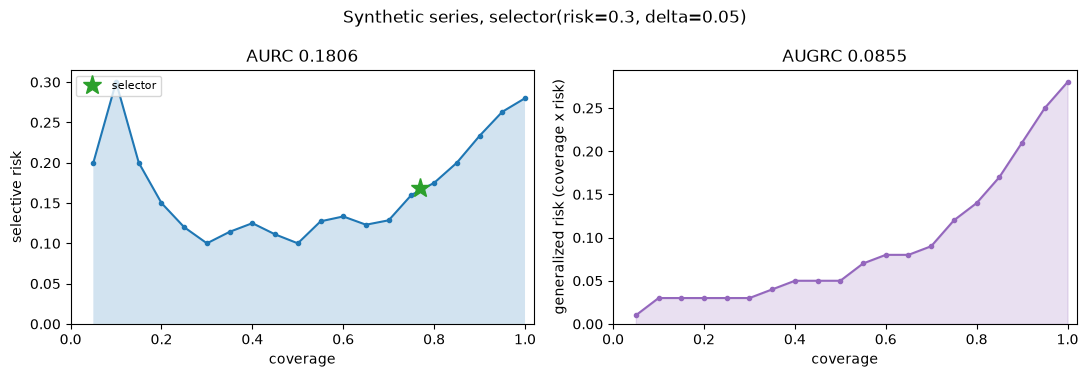

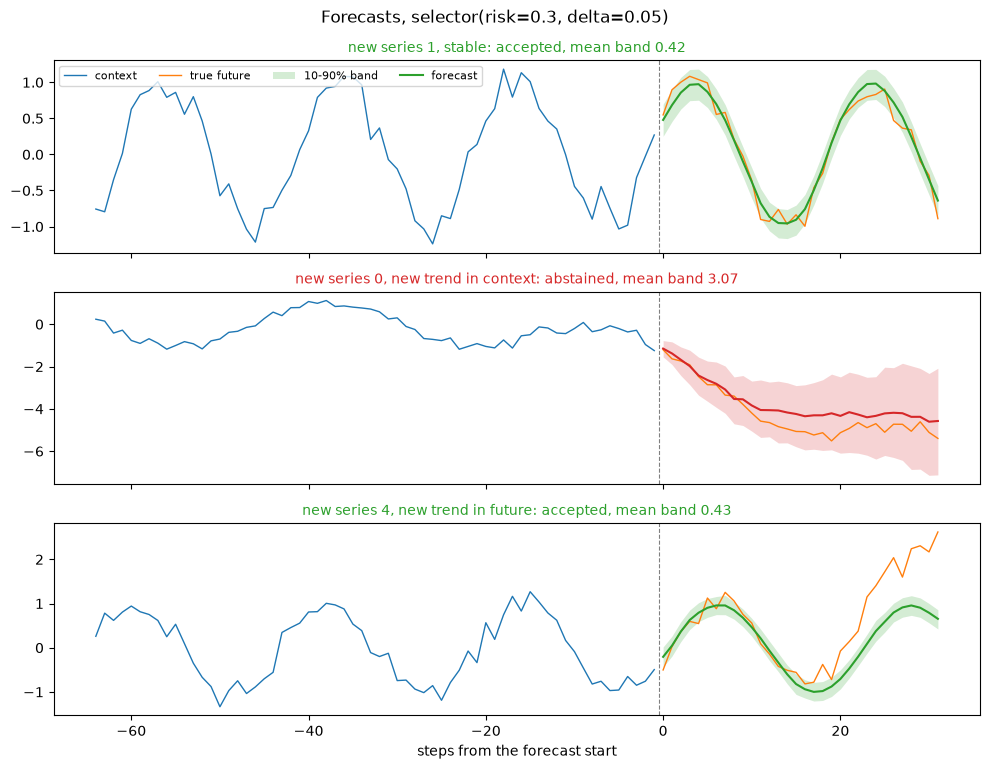

In [30]:
from probly.method import cast
from probly.predictor import RepresentationPredictor

# The quantile forecasts are already the representation, so probly only passes them on.
model = cast(forecast, predictor_type=RepresentationPredictor)

# Accept as many series as possible such that, with probability 95%, at most 10% of the accepted
# forecasts fail. The series are independent, which this guarantee needs.
selective_model = selective_predictor(
    model, selector=selector(risk=0.3, delta=0.05), notion=mean_band, decider=median_forecast, loss=failed
)

past, future = slice(None, CONTEXT), slice(CONTEXT, None)
selective_model.calibrate(ts_sel[:, future], ts_sel[:, past])
result = selective_model.evaluate(ts_eval[:, future], ts_eval[:, past], metrics=["aurc", "augrc", *CURVE])
predictions = selective_model.predict(ts_new[:, past])

show_evaluation(result, title=f"Synthetic series, {selective_model.selector}")
plot_series(ts_new, kind_new, predictions, forecast(ts_new[:, past]), title=f"Forecasts, {selective_model.selector}")